# Land-only spin-ups after the CO₂ fix: are they in equilibrium?

**Runs (2026-10-23 → 10-24, 100 yr each, `CLM_CO2_TYPE=diagnostic`, `CCSM_BGC=CO2A`).** CLM takes the CO₂ from the cplhist forcing, as in the coupled runs.

| Label | Script | Case | Surfdata |
|---|---|---|---|
| `PD_LCC` | 12b | `I2000Clm50BgcCropCplHist_lcc_f19_f19-20261023` | LPJ-GUESS 2100 |
| `FUT_CTRL` | 22c | `I2100ssp585Clm50BgcCropCplHist_ctrl_f19_f19-20261023` | CTRL (simyr2000) |
| `FUT_LCC` | 22b | `I2100ssp585Clm50BgcCropCplHist_lcc_f19_f19-20261023` | LPJ-GUESS 2100 |

For reference (dashed lines), the **old** runs: `PD_LCC_old` (`I2000…-20260925`, constant 367 ppm) and `FUT_LCC_old_bug` (`I2100…-20260924`, constant 284 ppm). They have no TWS or TOTVEGN.

**Criterion (user, 2026-10-22).** The short-term state (TWS, H2OSOI and TSOI at 1.06 m) must be in equilibrium at hand-over (year 100). Carbon (GPP, TOTVEGC, TOTVEGN) is shown for information only.
- **Drift test:** `ratio = |OLS trend over the last 10 yr, per decade| / IAV`, where IAV = SD of the detrended last 10 annual values. Below 1, the drift over a decade is smaller than the year-to-year noise. It is descriptive, not a hard threshold.
- **Rolling derivative:** `d(y) = (X[y] − X[y−20]) / 20` of the 20-yr trailing mean, against ± IAV/20.
- **Members agree (FUT only):** FUT_LCC − FUT_CTRL over the last 10 yr, outside the modified cells, in units of FUT_CTRL's IAV. Same forcing and set-up, different surfdata only at 46–82°N, so Δ should be ≈ 0 there. PD has no CTRL land-only run.

Regions: modified cells; >45°N unmodified; tropics 30°S–30°N. Weights = `area × landfrac`. Annual means weighted by `time_bounds` length.

In [1]:
import os
os.environ.setdefault('HDF5_USE_FILE_LOCKING', 'FALSE')  # before netCDF4/xarray import
from pathlib import Path
import re
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import netCDF4

# New runs: Betzy work archive first (complete), NIRD archive as fallback; old runs: NIRD archive.
ARCHIVES = [Path('/cluster/work/users/adelez/archive'), Path('/nird/datapeak/NS9188K/adelez/BRL-FRST-XPSN_archive')]
MASK_FILE = Path('../lcc-modified-cells/modified_cells.nc')
OUT = Path('check_land_only_equilibrium_after_co2_fix_outputs')
CACHE = OUT / 'cache'  # regenerable annual means; delete or set REBUILD_CACHE = True after changing inputs
CACHE.mkdir(parents=True, exist_ok=True)
REBUILD_CACHE = False

RUNS = pd.DataFrame([
    ('PD_LCC',          'PD',  'LCC',  'new', 'I2000Clm50BgcCropCplHist_lcc_f19_f19-20261023'),
    ('FUT_CTRL',        'FUT', 'CTRL', 'new', 'I2100ssp585Clm50BgcCropCplHist_ctrl_f19_f19-20261023'),
    ('FUT_LCC',         'FUT', 'LCC',  'new', 'I2100ssp585Clm50BgcCropCplHist_lcc_f19_f19-20261023'),
    ('PD_LCC_old',      'PD',  'LCC',  'old', 'I2000Clm50BgcCropCplHist_f19_f19-20260925'),
    ('FUT_LCC_old_bug', 'FUT', 'LCC',  'old', 'I2100ssp585Clm50BgcCropCplHist_f19_f19-20260924'),
], columns=['run', 'period', 'branch', 'version', 'case']).set_index('run')
NEW = list(RUNS.index[RUNS.version == 'new'])

VARS = ['TLAI', 'HTOP', 'TWS', 'H2OSOI_1m', 'TSOI_1m', 'GPP', 'TOTVEGC', 'TOTVEGN', 'CO2_ppm']
SOIL = {'H2OSOI_1m': 'H2OSOI', 'TSOI_1m': 'TSOI'}
SOIL_INDEX = 8  # levgrnd[8] = 1.06 m (asserted)
SHORT_TERM = ['TWS', 'H2OSOI_1m', 'TSOI_1m']
CARBON = ['GPP', 'TOTVEGC', 'TOTVEGN']
ROLL, LAST = 20, 10
COLOR = {'PD_LCC': '#4daf4a', 'FUT_CTRL': '#1f77b4', 'FUT_LCC': '#d95f02', 'PD_LCC_old': '#4daf4a', 'FUT_LCC_old_bug': '#d95f02'}

## 1. Read the annual means

One cache file per run in `check_land_only_equilibrium_after_co2_fix_outputs/cache/`. Only complete years (365 days) are kept. `CO2_ppm` = `PCO2/PBOT × 10⁶` (absent in the old runs).

In [2]:
def hist_files(case):
    for root in ARCHIVES:
        files = sorted((root / case / 'lnd/hist').glob('*.clm2.h0.*.nc'))
        if files:
            return files
    raise FileNotFoundError(case)

def read_file(path):
    with netCDF4.Dataset(path) as d:
        t = d['time']
        assert t.calendar == 'noleap' and re.fullmatch(r'days since \d{4}-01-01( 00:00:00)?', t.units), (path, t.units)
        bounds = d['time_bounds'][:].astype(float)
        mid = bounds.mean(1)
        out = dict(mid=mid, year=int(t.units.split()[2][:4]) + np.floor(mid / 365).astype(int), days=bounds[:, 1] - bounds[:, 0])
        for v in VARS:
            if v in d.variables:
                out[v] = np.ma.filled(d[v][:].astype(float), np.nan)
        for new, old in SOIL.items():
            if old in d.variables:
                assert abs(float(d['levgrnd'][SOIL_INDEX]) - 1.06) < 0.01, f'{path}: soil levels changed'
                out[new] = np.ma.filled(d[old][:, SOIL_INDEX].astype(float), np.nan)
        if {'PCO2', 'PBOT'} <= set(d.variables):
            out['CO2_ppm'] = np.ma.filled((d['PCO2'][:] / d['PBOT'][:] * 1e6).astype(float), np.nan)
    return out

def annual_means(case):
    files = hist_files(case)
    parts = [read_file(f) for f in files]
    mid = np.concatenate([p['mid'] for p in parts])
    assert len(np.unique(mid)) == len(mid), f'{case}: duplicated time steps'
    year = np.concatenate([p['year'] for p in parts])
    days = np.concatenate([p['days'] for p in parts])
    keep = [y for y in np.unique(year) if abs(days[year == y].sum() - 365) < 0.5]
    with netCDF4.Dataset(files[0]) as d:
        coords = dict(lat=d['lat'][:].data, lon=d['lon'][:].data)
        grid = {v: (('lat', 'lon'), np.ma.filled(d[v][:].astype(float), np.nan)) for v in ('area', 'landfrac')}
        units = {v: d[SOIL.get(v, v)].units for v in VARS if SOIL.get(v, v) in d.variables}
    data = {}
    for v in [v for v in VARS if all(v in p for p in parts)]:
        x = np.concatenate([p[v] for p in parts])
        rows = []
        for y in keep:
            sel = year == y
            total = np.nansum(x[sel] * days[sel][:, None, None], 0)
            total[np.isnan(x[sel]).all(0)] = np.nan
            rows.append(total / days[sel].sum())
        data[v] = (('year', 'lat', 'lon'), np.stack(rows), {'units': 'ppm' if v == 'CO2_ppm' else units.get(v, '?')})
    return xr.Dataset({**data, **grid}, coords=dict(year=keep, **coords), attrs=dict(case=case, source=str(files[0].parent)))

def load_run(run):
    path = CACHE / f'annual_{run}.nc'
    if path.is_file() and not REBUILD_CACHE:
        with xr.open_dataset(path) as ds:
            return ds.load()
    ann = annual_means(RUNS.loc[run, 'case'])
    tmp = path.with_name(path.stem + '.tmp.nc')
    ann.to_netcdf(tmp)
    os.replace(tmp, path)
    return ann

ANN = {run: load_run(run) for run in RUNS.index}
ref = ANN['FUT_CTRL']
for run, a in ANN.items():
    assert np.array_equal(a.lat, ref.lat) and np.array_equal(a.lon, ref.lon), run
    assert np.allclose(a.landfrac, ref.landfrac, equal_nan=True), run
print(pd.DataFrame({r: dict(years=f"{int(a.year[0])}–{int(a.year[-1])} ({a.sizes['year']})", source=a.source,
                            vars=', '.join(v for v in VARS if v in a)) for r, a in ANN.items()}).T.to_string())

                       years                                                                                            source                                                                 vars
PD_LCC           1–100 (100)         /cluster/work/users/adelez/archive/I2000Clm50BgcCropCplHist_lcc_f19_f19-20261023/lnd/hist  TLAI, HTOP, TWS, H2OSOI_1m, TSOI_1m, GPP, TOTVEGC, TOTVEGN, CO2_ppm
FUT_CTRL         1–100 (100)  /cluster/work/users/adelez/archive/I2100ssp585Clm50BgcCropCplHist_ctrl_f19_f19-20261023/lnd/hist  TLAI, HTOP, TWS, H2OSOI_1m, TSOI_1m, GPP, TOTVEGC, TOTVEGN, CO2_ppm
FUT_LCC          1–100 (100)   /cluster/work/users/adelez/archive/I2100ssp585Clm50BgcCropCplHist_lcc_f19_f19-20261023/lnd/hist  TLAI, HTOP, TWS, H2OSOI_1m, TSOI_1m, GPP, TOTVEGC, TOTVEGN, CO2_ppm
PD_LCC_old       1–100 (100)             /cluster/work/users/adelez/archive/I2000Clm50BgcCropCplHist_f19_f19-20260925/lnd/hist                               TLAI, H2OSOI_1m, TSOI_1m, GPP, TOTVEGC
FUT_LCC_old_bug  1–1

In [3]:
mask = xr.open_dataset(MASK_FILE).modified.astype(bool)
assert np.allclose(mask.lat, ref.lat) and np.allclose(mask.lon, ref.lon)
mask = mask.assign_coords(lat=ref.lat, lon=ref.lon)
LAND = ref.landfrac > 0
LAT = ref.lat.broadcast_like(LAND)
REGIONS = {
    'modified cells': LAND & mask,
    '>45N unmodified': LAND & (LAT > 45) & ~mask,
    'tropics 30S-30N': LAND & (abs(LAT) <= 30),
}
W = ref.area * ref.landfrac

def regional_mean(field, region):
    w = W.where(REGIONS[region] & np.isfinite(field))
    return (field * w).sum(('lat', 'lon')) / w.sum(('lat', 'lon'))

def per_year(v, field):
    return field * 86400 * 365 if v == 'GPP' else field

def units_of(v):
    return 'gC/m^2/yr' if v == 'GPP' else next(ANN[r][v].attrs['units'] for r in RUNS.index if v in ANN[r])

SERIES = {(run, r, v): regional_mean(per_year(v, ANN[run][v]), r)
          for run in RUNS.index for r in REGIONS for v in VARS if v in ANN[run]}

## 2. CO₂ seen by CLM

Global land median of the annual `PCO2/PBOT × 10⁶`, first and last year. Expected: ≈370 ppm (PD) and ≈1134–1142 ppm (FUT), as in the coupled runs.

In [4]:
co2 = pd.DataFrame({run: dict(first_year=float(np.nanmedian(ANN[run].CO2_ppm.isel(year=0).where(LAND))),
                              last_year=float(np.nanmedian(ANN[run].CO2_ppm.isel(year=-1).where(LAND))))
                    for run in NEW}).T.round(1)
co2.to_csv(OUT / 'co2_seen.csv')
co2

,first_year,last_year
PD_LCC,369.1,369.1
FUT_CTRL,1135.2,1135.2
FUT_LCC,1135.2,1135.2


## 3. Time series

Thin lines: annual means; thick lines: 20-yr trailing mean. Solid lines are the new runs, dashed lines the old ones (for reference only).

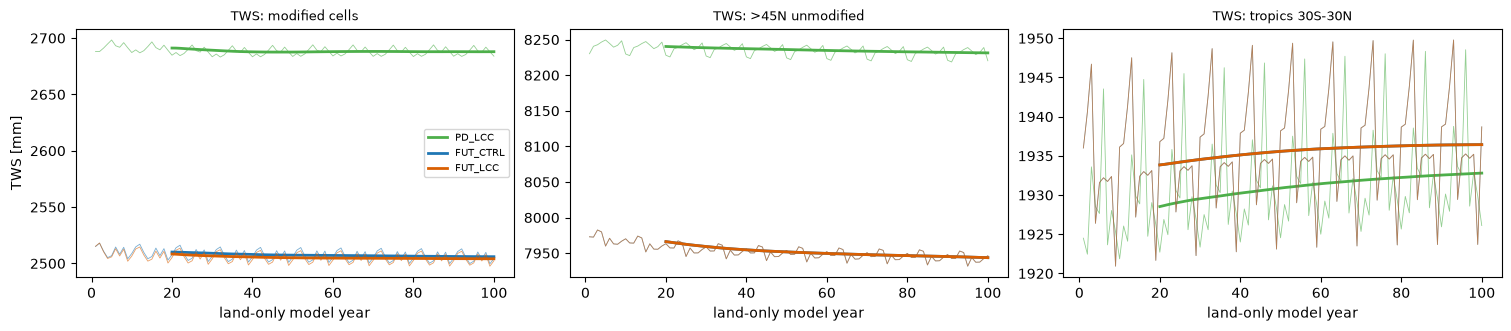

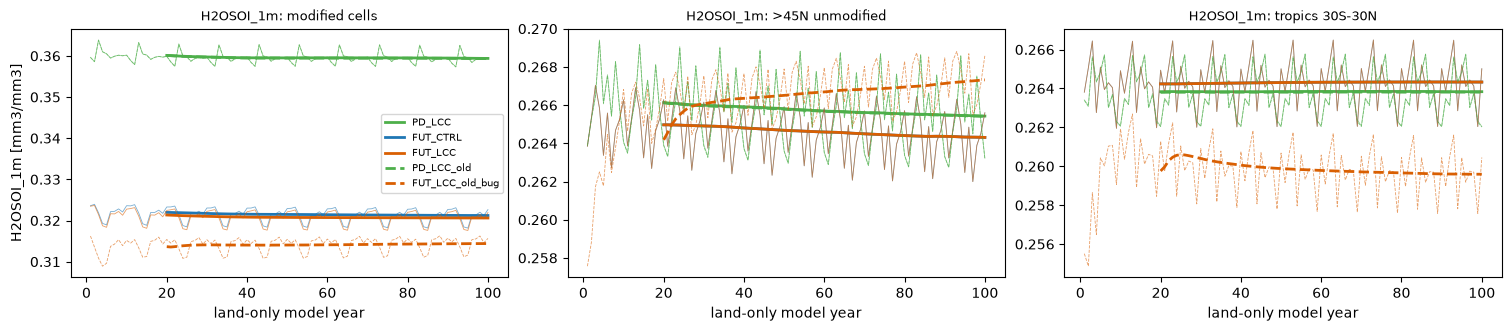

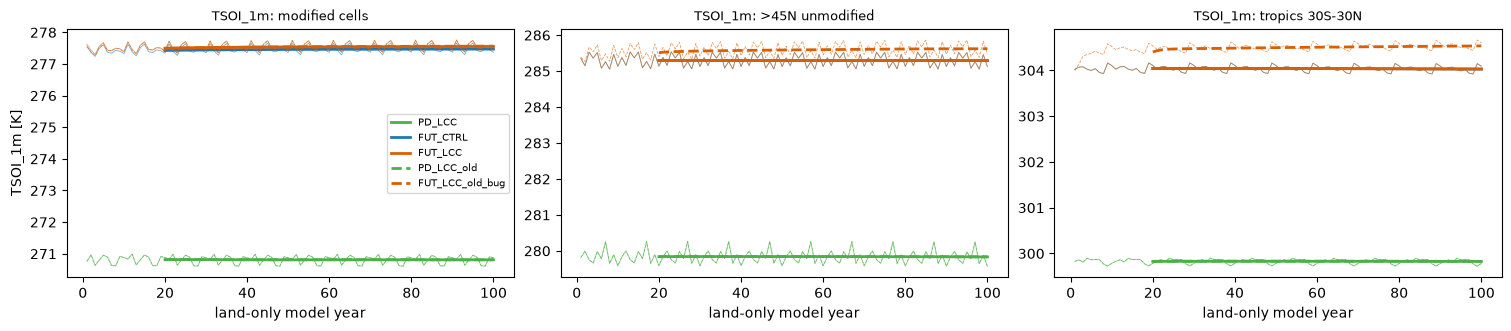

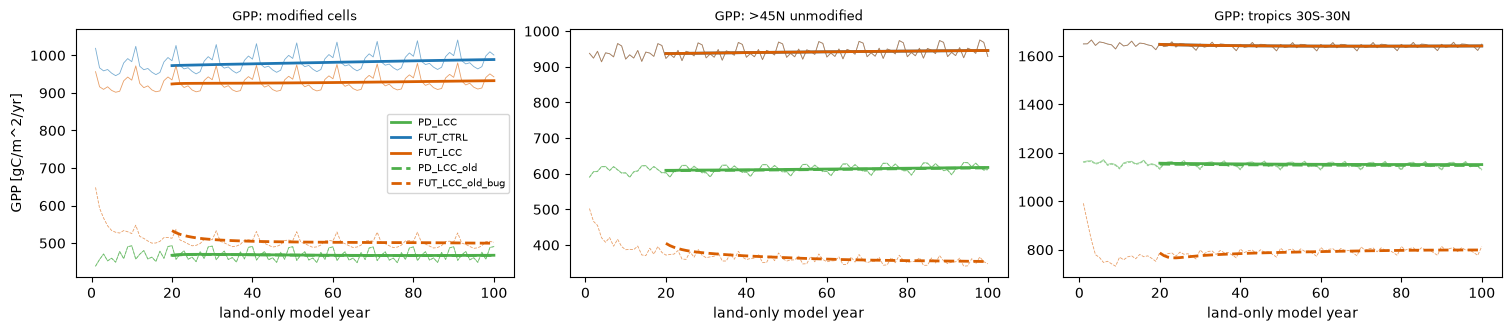

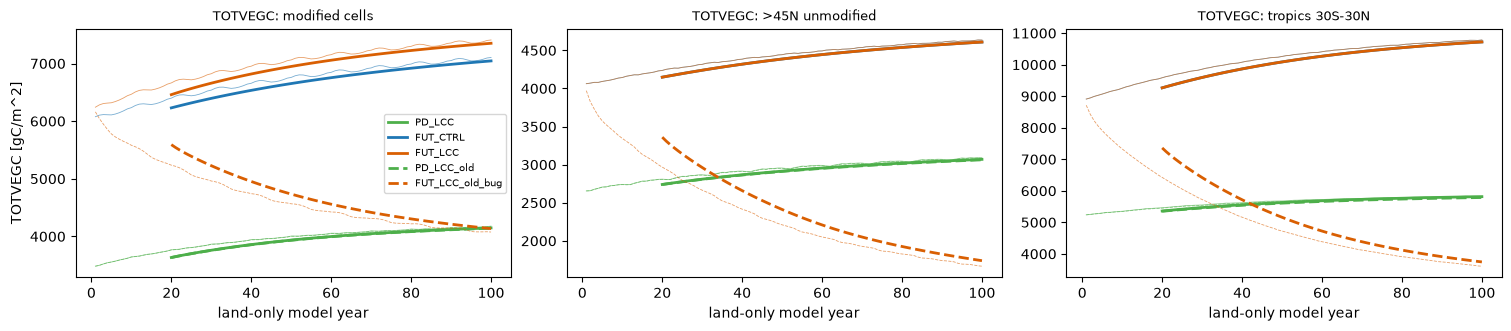

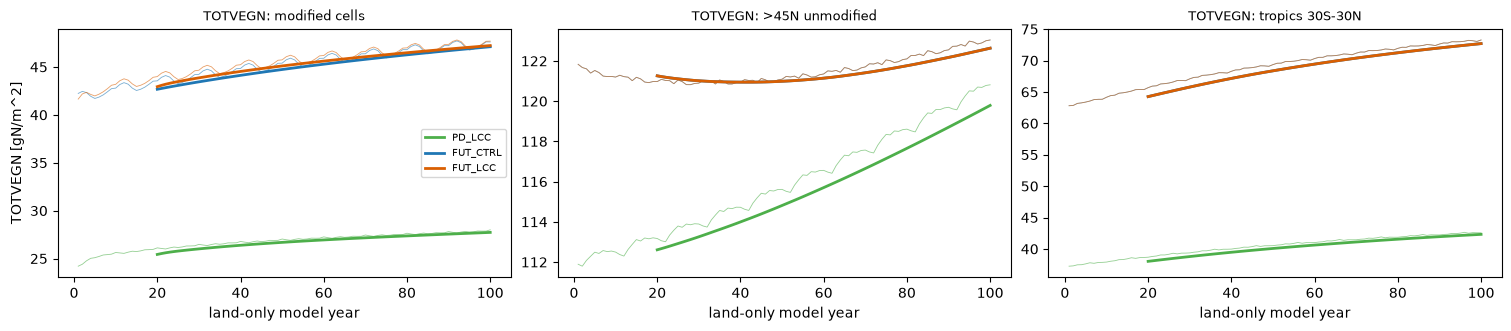

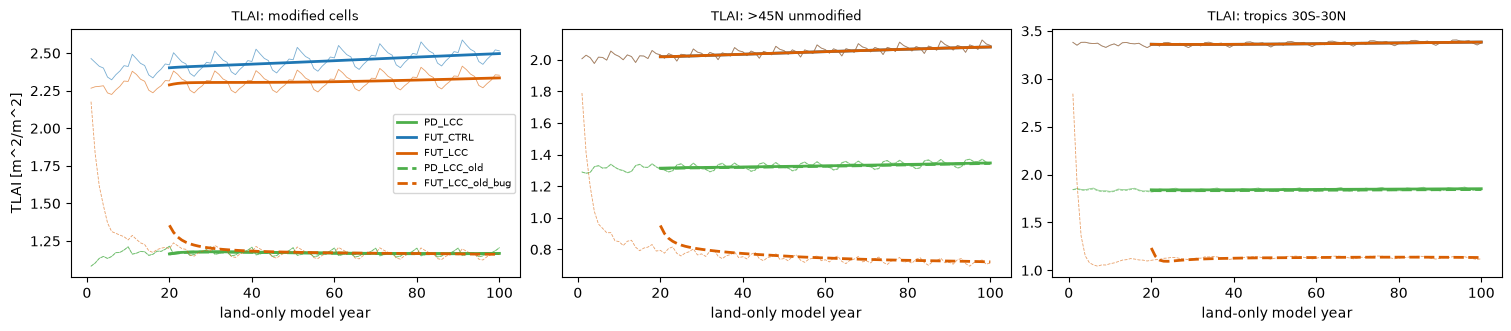

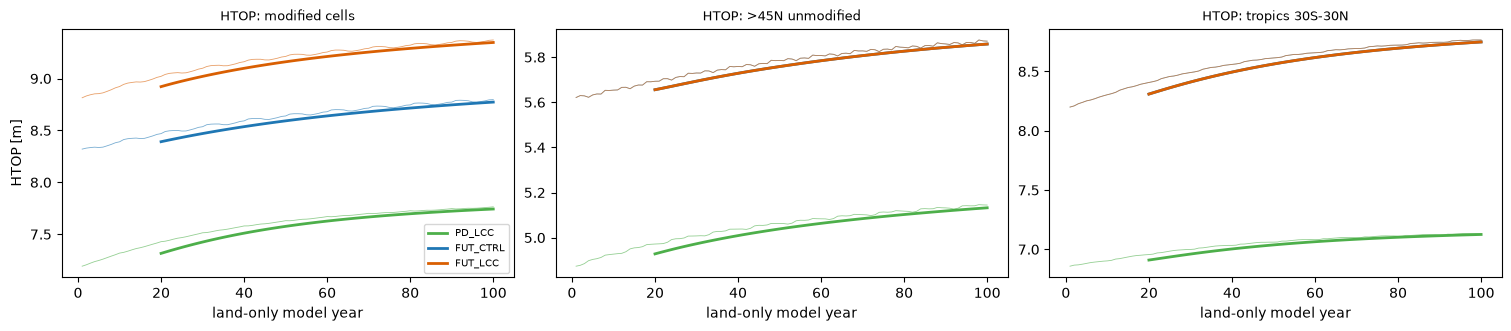

In [5]:
def series_figure(v):
    fig, axes = plt.subplots(1, len(REGIONS), figsize=(5 * len(REGIONS), 3.2), layout='constrained')
    for ax, region in zip(axes, REGIONS):
        for run, s in RUNS.iterrows():
            if (run, region, v) not in SERIES:
                continue
            y = SERIES[run, region, v]
            ls = '-' if s.version == 'new' else '--'
            ax.plot(y.year, y, color=COLOR[run], lw=0.6, ls=ls, alpha=0.6)
            ax.plot(y.year, y.rolling(year=ROLL).mean(), color=COLOR[run], lw=2, ls=ls, label=run)
        ax.set_title(f'{v}: {region}', fontsize=9)
        ax.set_xlabel('land-only model year')
    axes[0].set_ylabel(f'{v} [{units_of(v)}]')
    axes[0].legend(fontsize=7)
    fig.savefig(OUT / f'fig_series_{v}.png', dpi=150)
    plt.show()

for v in SHORT_TERM + CARBON + ['TLAI', 'HTOP']:
    series_figure(v)

## 4. Derivative of the 20-yr rolling mean (new runs)

Dotted lines: ± IAV / 20 yr, where IAV is the SD of the detrended last 20 annual values. A derivative inside the band means the 20-yr mean changes by less than one year of noise per year.

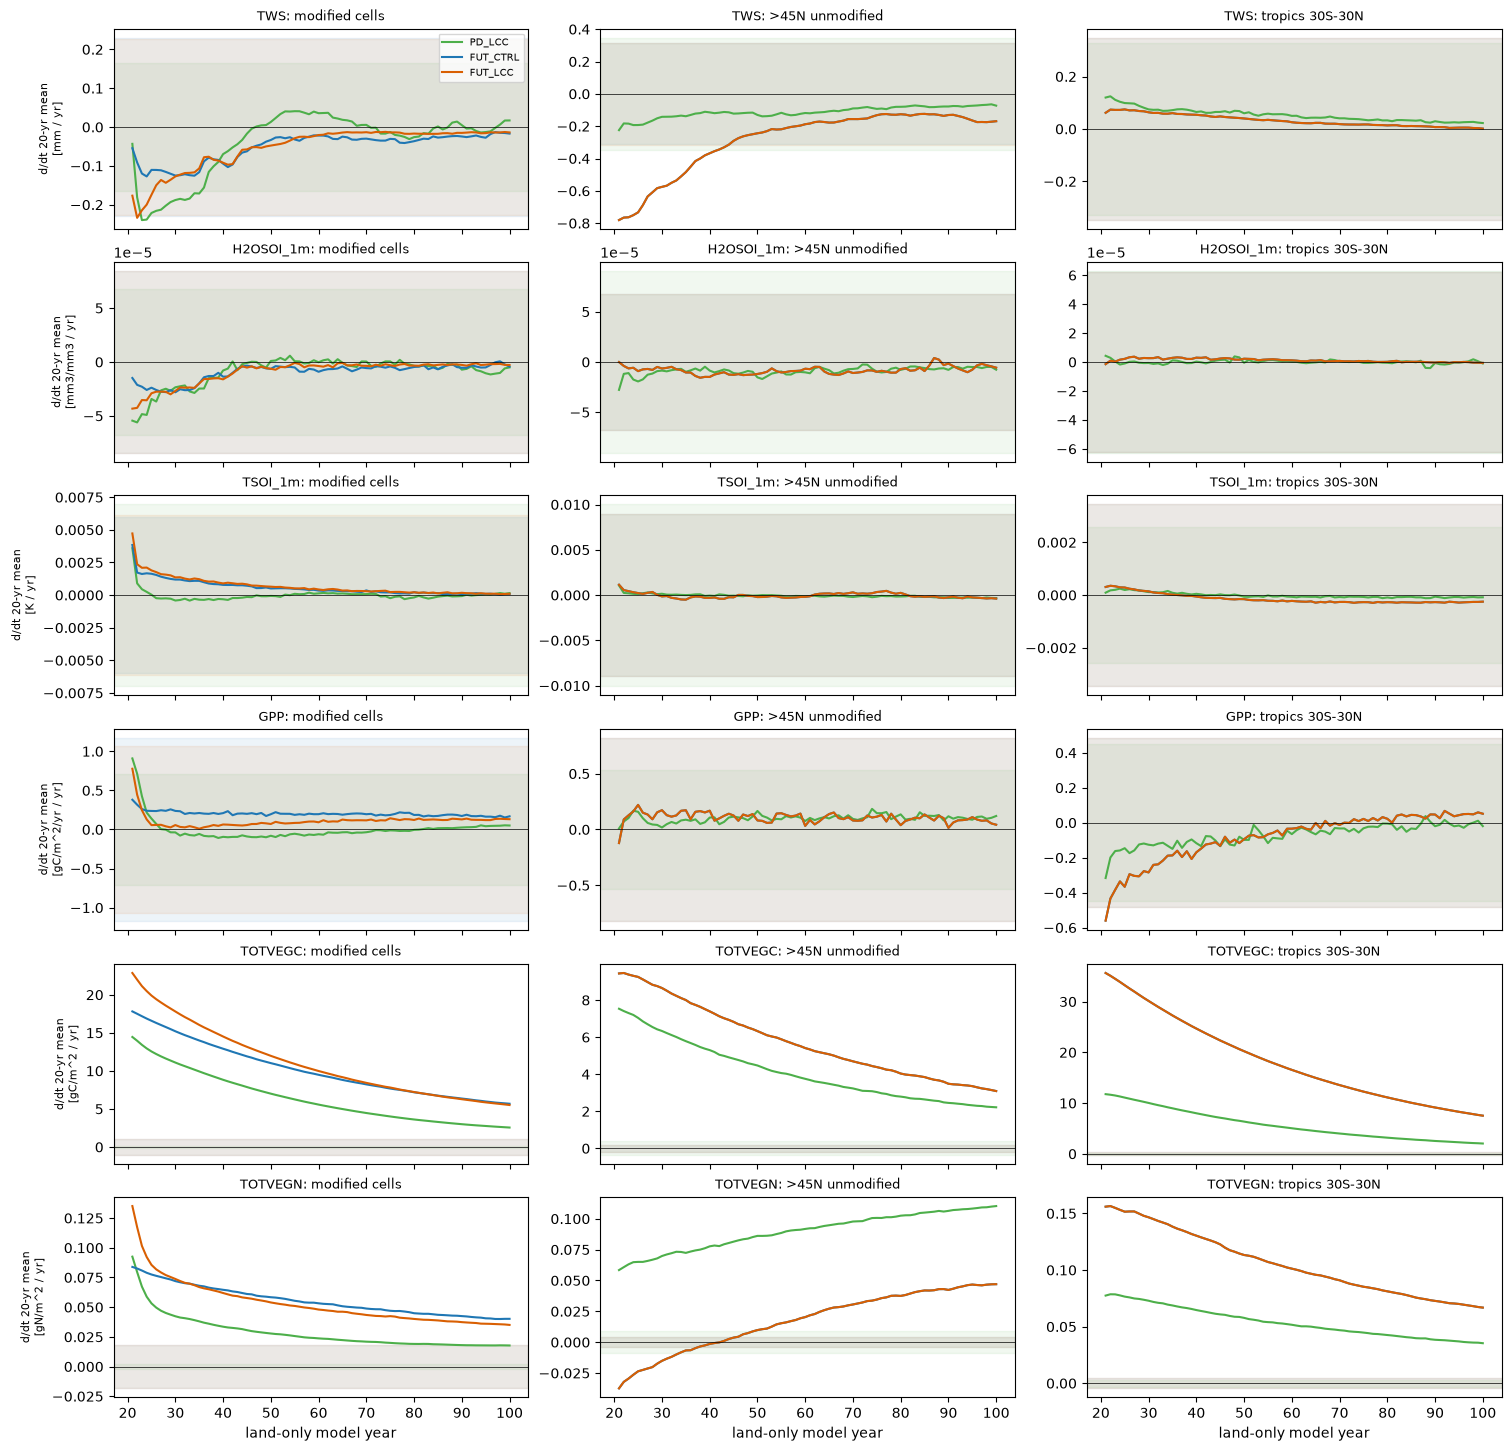

In [6]:
def detrended_sd(y):
    x = y.year.values.astype(float)
    return float(np.std(y.values - np.polyval(np.polyfit(x, y.values, 1), x), ddof=2))

fig, axes = plt.subplots(len(SHORT_TERM + CARBON), len(REGIONS), figsize=(5 * len(REGIONS), 2.4 * len(SHORT_TERM + CARBON)),
                         sharex=True, layout='constrained')
for i, v in enumerate(SHORT_TERM + CARBON):
    for j, region in enumerate(REGIONS):
        ax = axes[i, j]
        for run in NEW:
            y = SERIES[run, region, v]
            d = y.rolling(year=ROLL).mean().diff('year')
            ax.plot(d.year, d, color=COLOR[run], label=run)
            band = detrended_sd(y.isel(year=slice(-ROLL, None))) / ROLL
            ax.axhspan(-band, band, color=COLOR[run], alpha=0.08)
        ax.axhline(0, color='k', lw=0.5)
        ax.set_title(f'{v}: {region}', fontsize=9)
        if j == 0:
            ax.set_ylabel(f'd/dt {ROLL}-yr mean\n[{units_of(v)} / yr]', fontsize=8)
axes[0, 0].legend(fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel('land-only model year')
fig.savefig(OUT / 'fig_rolling_derivative.png', dpi=150)
plt.show()

## 5. Verdict: cycle-to-cycle drift (main test)

**The forcing repeats every 10 years.** `DATM_CPLHIST_YR_START/END = 11/20` in all three cases: the datm loops years 11–20 of the coupled spin-up (a, `xmlquery`). Year *y* and year *y − 10* therefore see identical forcing, so `X[y] − X[y−10]` contains only the land's own drift.
- **drift per cycle** = mean(years 91–100) − mean(years 81–90).
- **ratio_cycle** = |drift per cycle| / IAV, where IAV = SD of the 10 annual values of the last cycle. That SD is variability forced by the 10 different forcing years.
- Below 1, one more decade of spin-up changes the state by less than the year-to-year spread the forcing produces. Short-term variables carry the flag `in_equilibrium` (ratio_cycle < 1).

In [7]:
CYCLE = 10
rows = []
for run in NEW:
    for region in REGIONS:
        for v in SHORT_TERM + CARBON:
            y = SERIES[run, region, v]
            last, prev = y.isel(year=slice(-CYCLE, None)), y.isel(year=slice(-2 * CYCLE, -CYCLE))
            drift = float(last.mean() - prev.mean())
            iav = float(last.std(ddof=1))
            rows.append(dict(run=run, region=region, variable=v, units=units_of(v), mean=float(last.mean()),
                             drift_per_cycle=drift, iav_sd=iav, ratio_cycle=abs(drift) / iav,
                             drift_pct_per_cycle=100 * drift / float(last.mean())))
cycle = pd.DataFrame(rows)
cycle['in_equilibrium'] = cycle.ratio_cycle < 1
cycle.to_csv(OUT / 'verdict_cycle_drift.csv', index=False)

short_c = cycle[cycle.variable.isin(SHORT_TERM)]
print('SHORT-TERM: |mean(91-100) - mean(81-90)| / IAV   (< 1 = in equilibrium)')
display(short_c.pivot_table(index=['variable', 'region'], columns='run', values='ratio_cycle')[NEW].round(2))
print('SHORT-TERM: drift per cycle (native units)')
display(short_c.pivot_table(index=['variable', 'region', 'units'], columns='run', values='drift_per_cycle')[NEW].round(4))
print('CARBON (information only): drift per cycle, %')
display(cycle[cycle.variable.isin(CARBON)].pivot_table(index=['variable', 'region'], columns='run',
                                                       values='drift_pct_per_cycle')[NEW].round(2))
print(f"Short-term cases with ratio_cycle >= 1: {int((~short_c.in_equilibrium).sum())} of {len(short_c)}")

SHORT-TERM: |mean(91-100) - mean(81-90)| / IAV   (< 1 = in equilibrium)


run                        PD_LCC  FUT_CTRL  FUT_LCC
variable  region                                    
H2OSOI_1m >45N unmodified    0.03      0.08     0.08
          modified cells     0.08      0.00     0.01
          tropics 30S-30N    0.00      0.00     0.00
TSOI_1m   >45N unmodified    0.02      0.02     0.02
          modified cells     0.01      0.00     0.01
          tropics 30S-30N    0.01      0.04     0.04
TWS       >45N unmodified    0.10      0.27     0.27
          modified cells     0.07      0.04     0.02
          tropics 30S-30N    0.03      0.00     0.00

SHORT-TERM: drift per cycle (native units)


run                                PD_LCC  FUT_CTRL  FUT_LCC
variable  region          units                             
H2OSOI_1m >45N unmodified mm3/mm3 -0.0001   -0.0001  -0.0001
          modified cells  mm3/mm3 -0.0001   -0.0000  -0.0000
          tropics 30S-30N mm3/mm3  0.0000   -0.0000  -0.0000
TSOI_1m   >45N unmodified K       -0.0035   -0.0032  -0.0032
          modified cells  K        0.0010    0.0006   0.0009
          tropics 30S-30N K       -0.0008   -0.0025  -0.0025
TWS       >45N unmodified mm      -0.7148   -1.7215  -1.7209
          modified cells  mm      -0.2387   -0.1766  -0.0942
          tropics 30S-30N mm       0.2261    0.0199   0.0199

CARBON (information only): drift per cycle, %


run                       PD_LCC  FUT_CTRL  FUT_LCC
variable region                                    
GPP      >45N unmodified    0.19      0.08     0.08
         modified cells     0.12      0.17     0.14
         tropics 30S-30N   -0.01      0.03     0.03
TOTVEGC  >45N unmodified    0.71      0.67     0.67
         modified cells     0.61      0.80     0.74
         tropics 30S-30N    0.34      0.69     0.69
TOTVEGN  >45N unmodified    0.92      0.39     0.39
         modified cells     0.63      0.84     0.74
         tropics 30S-30N    0.83      0.91     0.91

Short-term cases with ratio_cycle >= 1: 0 of 27


### Cycle means over the whole run

Mean of each 10-yr forcing cycle (1–10, 11–20, …, 91–100) for the short-term variables. The cycle means of a run in equilibrium are flat.

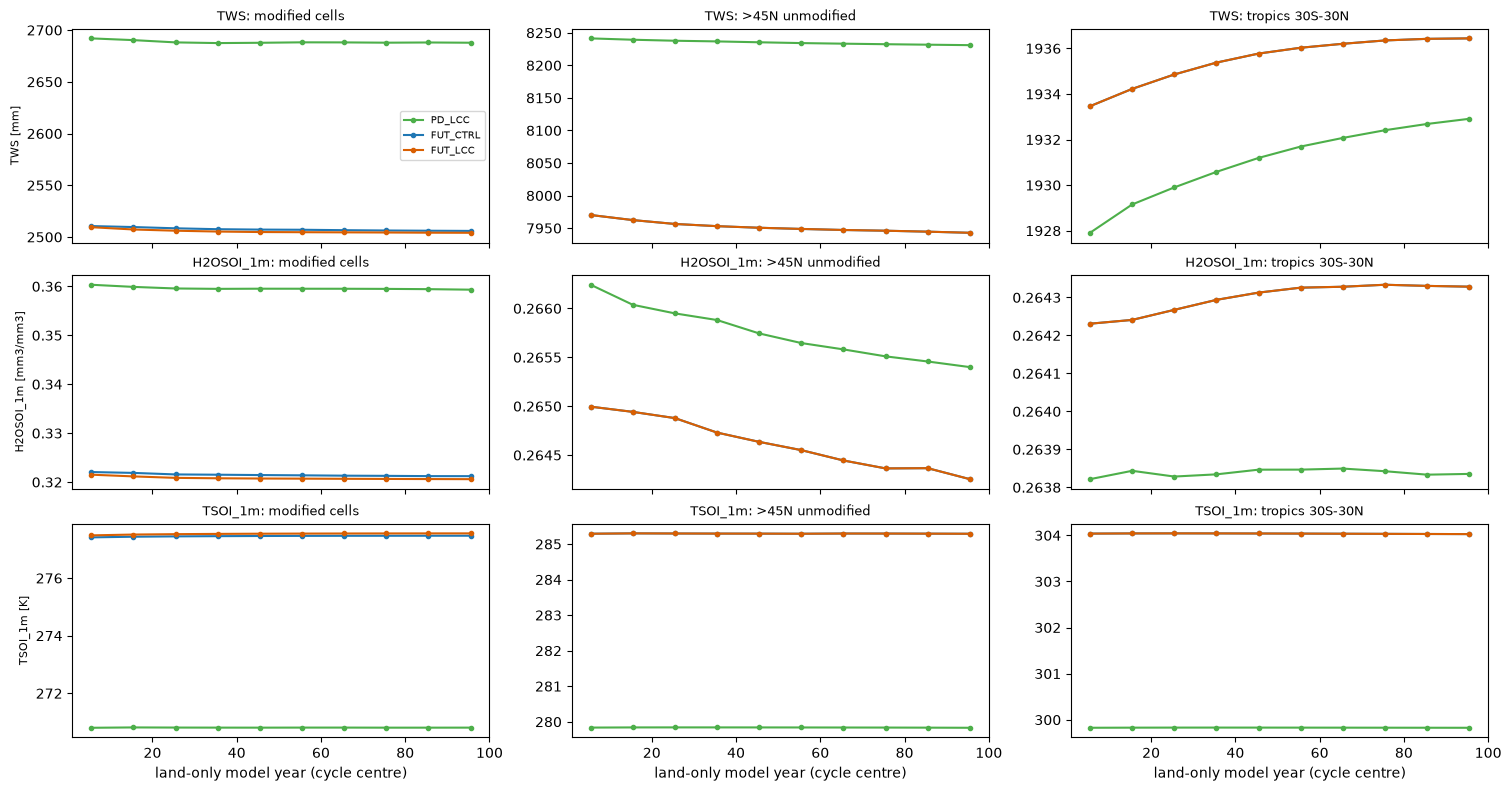

In [8]:
fig, axes = plt.subplots(len(SHORT_TERM), len(REGIONS), figsize=(5 * len(REGIONS), 2.6 * len(SHORT_TERM)),
                         sharex=True, layout='constrained')
for i, v in enumerate(SHORT_TERM):
    for j, region in enumerate(REGIONS):
        ax = axes[i, j]
        for run in NEW:
            y = SERIES[run, region, v]
            cyc = y.coarsen(year=CYCLE).mean()
            ax.plot(cyc.year, cyc, marker='o', ms=3, color=COLOR[run], label=run)
        ax.set_title(f'{v}: {region}', fontsize=9)
        if j == 0:
            ax.set_ylabel(f'{v} [{units_of(v)}]', fontsize=8)
axes[0, 0].legend(fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel('land-only model year (cycle centre)')
fig.savefig(OUT / 'fig_cycle_means_short_term.png', dpi=150)
plt.show()

### For comparison: OLS trend over the last 10 years

This is the test used in the earlier notebooks: `ratio = |trend per decade| / IAV`. **With a 10-yr forcing loop it is misleading**: the 10 years are one forcing cycle, so the "trend" is mostly the sequence of forcing years (warm and cold years in a fixed order), not drift. It is kept only to compare with the earlier verdicts.

In [9]:
rows = []
for run in NEW:
    for region in REGIONS:
        for v in SHORT_TERM + CARBON:
            y = SERIES[run, region, v]
            last = y.isel(year=slice(-LAST, None))
            trend = LAST * np.polyfit(last.year.values.astype(float), last.values, 1)[0]
            iav = detrended_sd(last)
            rows.append(dict(run=run, region=region, variable=v, units=units_of(v), mean=float(last.mean()),
                             trend_per_decade=trend, iav_sd=iav, ratio=abs(trend) / iav,
                             trend_pct_per_decade=100 * trend / float(last.mean()),
                             roll20_deriv_last=float(y.rolling(year=ROLL).mean().diff('year')[-1])))
verdict = pd.DataFrame(rows)
verdict['drift_below_noise'] = verdict.ratio < 1
verdict.to_csv(OUT / 'verdict_last10yr.csv', index=False)

short = verdict[verdict.variable.isin(SHORT_TERM)]
print('SHORT-TERM: ratio |trend/decade| / IAV  (< 1 = drift below noise)')
display(short.pivot_table(index=['variable', 'region'], columns='run', values='ratio')[NEW].round(2))
print('SHORT-TERM: trend per decade (native units)')
display(short.pivot_table(index=['variable', 'region', 'units'], columns='run', values='trend_per_decade')[NEW].round(4))
print('CARBON (information only): trend, % per decade')
carbon = verdict[verdict.variable.isin(CARBON)]
display(carbon.pivot_table(index=['variable', 'region'], columns='run', values='trend_pct_per_decade')[NEW].round(2))
print(f"Short-term cases with ratio >= 1: {int((~short.drift_below_noise).sum())} of {len(short)}")

SHORT-TERM: ratio |trend/decade| / IAV  (< 1 = drift below noise)


run                        PD_LCC  FUT_CTRL  FUT_LCC
variable  region                                    
H2OSOI_1m >45N unmodified    0.19      0.06     0.06
          modified cells     0.25      0.10     0.04
          tropics 30S-30N    1.51      0.93     0.93
TSOI_1m   >45N unmodified    0.56      1.03     1.03
          modified cells     0.33      1.17     1.17
          tropics 30S-30N    2.16      0.29     0.29
TWS       >45N unmodified    0.42      0.67     0.67
          modified cells     0.57      1.43     1.53
          tropics 30S-30N    0.45      1.86     1.86

SHORT-TERM: trend per decade (native units)


run                                PD_LCC  FUT_CTRL  FUT_LCC
variable  region          units                             
H2OSOI_1m >45N unmodified mm3/mm3  0.0004    0.0001   0.0001
          modified cells  mm3/mm3  0.0004    0.0002   0.0001
          tropics 30S-30N mm3/mm3 -0.0019   -0.0012  -0.0012
TSOI_1m   >45N unmodified K       -0.1187   -0.1868  -0.1868
          modified cells  K       -0.0494   -0.1415  -0.1443
          tropics 30S-30N K       -0.1011    0.0215   0.0215
TWS       >45N unmodified mm       3.0845   -4.4460  -4.4511
          modified cells  mm       1.9045   -6.5331  -6.7927
          tropics 30S-30N mm      -3.1050  -12.1744 -12.1744

CARBON (information only): trend, % per decade


run                       PD_LCC  FUT_CTRL  FUT_LCC
variable region                                    
GPP      >45N unmodified    1.12      1.90     1.90
         modified cells     5.39     -0.78    -0.95
         tropics 30S-30N   -1.78     -0.25    -0.25
TOTVEGC  >45N unmodified    1.25      0.45     0.45
         modified cells     0.64      0.22     0.20
         tropics 30S-30N    0.31      0.52     0.52
TOTVEGN  >45N unmodified    1.22      0.27     0.27
         modified cells     0.94     -0.18    -0.29
         tropics 30S-30N    0.70      0.63     0.63

Short-term cases with ratio >= 1: 10 of 27


## 6. Do the FUT members share the same state? FUT_LCC − FUT_CTRL, last 10 years

Δ of the 10-yr means in units of FUT_CTRL's detrended IAV. Outside the modified cells the two runs differ only through the land-cover change far away, which a land-only run cannot transmit (no atmosphere). So Δ should be ≈ 0 there. With the old, buggy FUT_LCC this test failed (e.g. tropics TSOI +6 IAV in the nudged years).

In [10]:
rows = []
for region in REGIONS:
    for v in SHORT_TERM + CARBON + ['TLAI', 'HTOP']:
        c = SERIES['FUT_CTRL', region, v].isel(year=slice(-LAST, None))
        l = SERIES['FUT_LCC', region, v].isel(year=slice(-LAST, None))
        sd = detrended_sd(c)
        rows.append(dict(region=region, variable=v, units=units_of(v), CTRL=float(c.mean()), LCC=float(l.mean()),
                         delta=float(l.mean() - c.mean()), delta_pct=100 * float(l.mean() - c.mean()) / float(c.mean()),
                         delta_in_iav=float(l.mean() - c.mean()) / sd if sd > 0 else np.nan))
members = pd.DataFrame(rows)
members.to_csv(OUT / 'FUT_LCC_minus_CTRL_last10yr.csv', index=False)
display(members.pivot_table(index='variable', columns='region', values='delta_in_iav').round(2))
display(members.pivot_table(index='variable', columns='region', values='delta_pct').round(2))

region,>45N unmodified,modified cells,tropics 30S-30N
variable,,,
GPP,0.0,-2.29,0.0
H2OSOI_1m,-0.0,-0.34,0.0
HTOP,-0.0,65.97,0.0
TLAI,0.0,-3.47,0.0
TOTVEGC,-0.0,14.75,0.0
TOTVEGN,-0.0,0.27,0.0
TSOI_1m,-0.0,0.68,0.0
TWS,0.0,-0.40,0.0


region,>45N unmodified,modified cells,tropics 30S-30N
variable,,,
GPP,0.0,-5.71,0.0
H2OSOI_1m,-0.0,-0.19,0.0
HTOP,-0.0,6.53,0.0
TLAI,0.0,-6.55,0.0
TOTVEGC,-0.0,4.31,0.0
TOTVEGN,-0.0,0.21,0.0
TSOI_1m,-0.0,0.03,0.0
TWS,0.0,-0.07,0.0


## Summary (run 2026-10-25, outputs saved in this notebook and in `check_land_only_equilibrium_after_co2_fix_outputs/`)

👉 **The three land-only spin-ups are in short-term equilibrium at year 100 and can hand over to the coupled spin-ups (13b, 23b, 23c).**

**CO₂ is right (a, §2):** CLM sees 369 ppm (PD) and 1135 ppm (FUT) from year 1 to year 100. The FUT runs show no collapse.

**Short-term state (a, §5, `verdict_cycle_drift.csv`):** the drift from the 9th to the 10th forcing cycle (years 81–90 → 91–100) is far below the interannual spread in every run, region and variable. ratio_cycle ≤ 0.27, **27/27 in equilibrium**.
| Largest drift per cycle | PD_LCC | FUT_CTRL / FUT_LCC |
|---|---|---|
| TWS, >45°N unmodified | −0.7 mm (ratio 0.10) | −1.7 mm (ratio 0.27) |
| TSOI at 1.06 m, any region | ≤ 0.004 K | ≤ 0.003 K |
| H2OSOI at 1.06 m, any region | ≤ 1e-4 mm³/mm³ | ≤ 1e-4 mm³/mm³ |

- **Slow creep remains, but it is small (a, cycle-means figure):** soil water >45°N falls and tropical TWS rises slowly in all runs. Over 100 years this is ≈0.001 mm³/mm³ and ≈5 mm (of ≈1930 mm).
- **The OLS test is misleading here (a, §5 comparison table):** it flags 10/27 cases with ratio ≥ 1. The forcing loops cplhist years 11–20, so a 10-yr window is one forcing cycle, and its "trend" is the order of the forcing years. Example: TSOI >45°N FUT gives −0.19 K/decade by OLS, but only −0.003 K from cycle to cycle. The earlier notebooks used OLS on the same kind of forcing loop, so their short-term ratios were pessimistic (b).

**Carbon (information only, a):** still rising, by 0.3–0.9 % per cycle for TOTVEGC and TOTVEGN, and < 0.2 % per cycle for GPP. This is not required by the criterion.

**FUT members (a, §6):** FUT_LCC − FUT_CTRL is exactly 0 outside the modified cells. That is expected: without an atmosphere, each column depends only on its own surfdata and the (identical) forcing. It confirms the two runs have identical set-ups. In the modified cells (last 10 yr): HTOP +6.5 % (+66 IAV), TOTVEGC +4.3 %, TLAI −6.6 %, GPP −5.7 %, TSOI +0.03 K, TWS −0.1 %.

**Caveat (b):** equilibrium under land-only forcing is not equilibrium in the coupled model. The coupled spin-ups (20 yr) and the free → nudged jump (`../../impact-of-nudging-on-land/`) still shift the state; the same jump in both members largely cancels in LCC − CTRL.

